In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import math

dados = pd.read_excel(r'CCPP\Folds5x2_pp.xlsx')
print(dados.columns)

Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='str')


In [3]:
# ── Configurações de Plotagem ────────────────────────────────────────────────
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

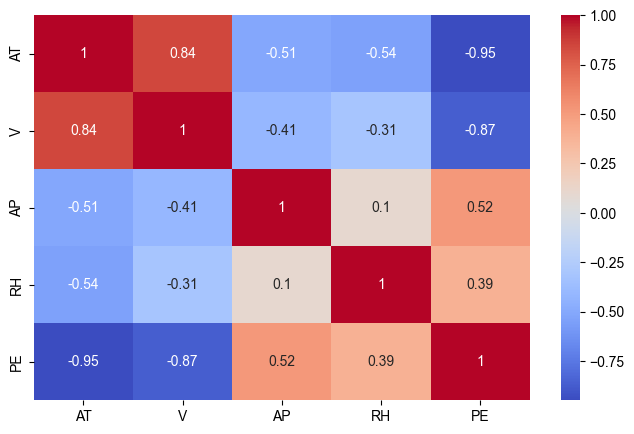

In [4]:
dados_num = dados.select_dtypes(include="number")
corr = dados_num.corr() 
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

Resposta 1)
As variaveis AP(Ambient Pressure) e RH(Relative Humidity) tiveram a maior correlação se comparado com as demais variaveis, elas tiveram uma taxa de correlação 0.52 e 0.39 respectivamente.

2. Calcule a correlac¸ao entre as vari ˜ aveis independentes (AT, V, AP, RH) entre si. Existe alguma relac¸ ´ ao forte ˜
entre elas? Se sim, isso pode indicar multicolinearidade.

Resposta 2)
As variaveis AT(Ambient Temperature) e V(Exhaust Vacuum) tem uma forte correlação em si, com uma taxa de correlação de 0.84

  3. Construa um modelo de regressao linear m´ultipla utilizando as vari ˜ aveis independentes (AT, V, AP, RH) para ´
prever a variavel dependente (PE). Divida os dados em treino (80%) e teste (20%).

In [5]:
x = dados.drop(columns=["PE"])
print(x.columns)

Index(['AT', 'V', 'AP', 'RH'], dtype='str')


In [6]:
y = dados.drop(columns=["AT", "V", "AP", "RH"])
print(y.columns)

Index(['PE'], dtype='str')


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
  x, y, test_size=0.2, random_state=42
)

print(f"Tamanho do dataset = {x.shape[0]} amostras")
print(f"Quantidade de amostras de treinamento = {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de teste = {X_test.shape[0]} amostras")

Tamanho do dataset = 9568 amostras
Quantidade de amostras de treinamento = 7654 amostras
Quantidade de amostras de teste = 1914 amostras


In [9]:
import numpy as np
Xdata = X_train.to_numpy()[:,0]
ydata = y_train.to_numpy().T

t1 = np.sum((Xdata - np.mean(Xdata))*(ydata - np.mean(ydata)))/np.sum((Xdata - np.mean(Xdata))**2)
t1

np.float64(-2.177091774538217)

In [10]:
t0 = np.mean(ydata) - t1*np.mean(Xdata)
t0

np.float64(497.1541677918609)

In [18]:
linear_regression = LinearRegression()
linear_regression.fit(X_train, y_train)

t0, t1 = linear_regression.intercept_, linear_regression.coef_
y_pred = linear_regression.predict(X_test)

print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred):.4f}")

R2 Score: 0.9301
MSE: 20.2737
